```python
# Copyright (c) 2026 Louis Gevers
# SPDX-License-Identifier: BSD-3-Clause
```

# Legged Robots Project - Task 2: Flat Terrain Analysis

In this notebook you will analyse the data produced by `01_flat_terrain.ipynb`:
training logs and evaluation rollouts.
There are no simulations here, so it does not need a GPU and can be restarted at any time.

**Before you start:** check out the metrics functions in `src/lr_project/metrics.py`.
This is the only source file that you will have to edit.
We provided two example implementations, but it is up to you to implement the relevant metrics using rollout data (see 2.0c) for your analyses.
There are two kinds of functions, recognizable by their output shape (`N` number of robots, `T` number of timesteps):
- **per-step signals**, shape `(N, T)`: one value per robot and per time step, e.g. to plot a quantity over time.
- **per-robot metrics**, shape `(N,)`: one value per robot, summarizing its whole rollout.

Thanks to `%autoreload`, edits to `metrics.py` are picked up without restarting the kernel.

**Rules for your analysis**
- Every number and figure must come from a cell in this notebook. 
Never copy numbers by hand.
- The sections below list the **minimum** we expect. 
Add any analysis, figure or metric that helps you answer the questions.
- Label every figure: axes with units, a legend when there are several curves, and a title.
- Write your answers under the **[ANSWER]** cells in markdown.
Remember that short and precise beats long.

In [1]:
%load_ext autoreload
%autoreload 2

import math
import numpy as np
import matplotlib.pyplot as plt

from lr_project.rollout import Rollout
from lr_project import registry, analysis, metrics

## 2.0 Collected data

We provide you with an example of how to load three kinds of data you have generated:
the list of runs, the training logs of a run, and its evaluation rollouts.
Run it as is, then reuse the patterns in your analysis sections.

### 2.0a Selecting runs of interest

`registry.runs` lists runs filtered by experiment and variant (the names used in `train.train`), sorted by creation time. 
`runs[-1]` is the latest run (it's a python list).

In [2]:
runs = registry.runs(
    experiment="flat",
    variant="baseline",
)
registry.show(runs)

| experiment | variant | created |
| --- | --- | --- |
| flat | baseline | 2026-11-11_17-29-23 |
| flat | baseline | 2026-11-11_18-38-41 |
| flat | baseline | 2026-11-14_12-02-24 |

In [3]:
run = runs[-1]
registry.show([run])

| experiment | variant | created |
| --- | --- | --- |
| flat | baseline | 2026-11-14_12-02-24 |

### 2.0b Training data

`analysis.load_training_logs` reads the curves logged during training and returns a dictionary `{curve name: (iterations, values)}`. 
`patterns` are regular expressions over the curve names, e.g. `"Episode_Reward/.*"` for all reward terms.
The curve names match the ones you see in TensorBoard.

In [4]:
train_metrics = analysis.load_training_logs(
    run_dir=run.path,
    patterns=["Train/mean_reward", "Train/mean_episode_length", "Episode_Reward/.*"],
)

print("Loaded training metrics:")
for metric in train_metrics.keys():
    print(f"- {metric!r}")

Loaded training metrics:
- 'Episode_Reward/body_angular_velocity_penalty'
- 'Episode_Reward/track_angular_velocity'
- 'Episode_Reward/joint_torques'
- 'Episode_Reward/leg_contact_penalty'
- 'Episode_Reward/feet_air_time'
- 'Episode_Reward/track_linear_velocity'
- 'Episode_Reward/base_contact_penalty'
- 'Episode_Reward/body_linear_velocity_penalty'
- 'Episode_Reward/body_tilt'
- 'Episode_Reward/action_rate'
- 'Train/mean_reward'
- 'Train/mean_episode_length'


Below we provide an example of plotting training logs, specifically the mean reward per learning iteration:

Loaded 500 iterations of mean reward with last 3 elements: [38.1068573  38.03544235 38.01832581]


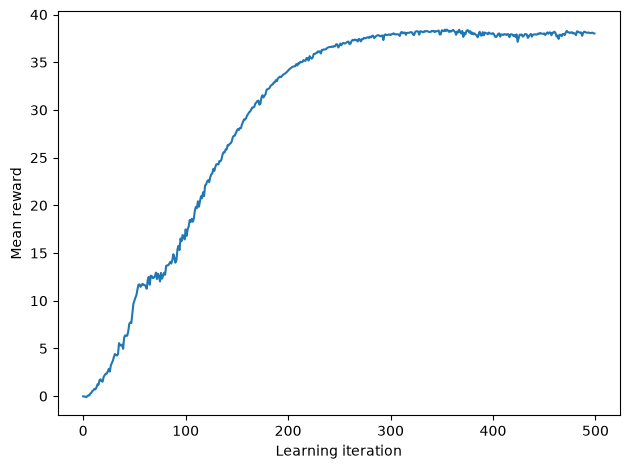

In [5]:
iterations, mean_reward = train_metrics["Train/mean_reward"]
print(f"Loaded {len(iterations)} iterations of mean reward with last 3 elements: {mean_reward[-3:]}")

fig, ax = plt.subplots()

ax.plot(iterations, mean_reward)
ax.set_xlabel("Learning iteration")
ax.set_ylabel("Mean reward")

fig.tight_layout()
plt.show()

### 2.0c Evaluation data

`Rollout.load` reads an evaluation saved in notebook 01. 
A `Rollout` holds numpy arrays for N robots and T time steps (see `src/lr_project/rollout.py` for all fields), for example:

| Field | Shape | Content |
| --- | --- | --- |
| `cmd` | (N, 3) | command of each robot $(v_x, v_y, \omega_z)$ |
| `alive` | (N,) | `True` if the robot never fell |
| `base_lin_vel`, `base_ang_vel` | (N, T, 3) | base velocities in the body frame |
| `base_pos`, `base_quat` | (N, T, 3), (N, T, 4) | base position and orientation in the world frame |
| `joint_pos`, `joint_vel`, `joint_torque` | (N, T, 12) | joint states and torques |
| `foot_contact`, `foot_height` | (N, T, 4) | contact flags and heights of the feet (FL, FR, RL, RR) |
| `foot_grf` | (N, T, 4, 3) | ground reaction forces on the feet |

Robots that fell distort most metrics: compute them on `rollouts.select(rollouts.alive)` and report the survival rate separately.

Below we provide some examples of how to take statistics from rollout data and making a simple figure:

Survival rate is 91.7% (330 out of 360 evaluations alive)
Average linear velocity error is 0.12 (std=0.05)
Robot 69 command: [ 0.    0.1  -0.25] (lin vel error: 0.10)


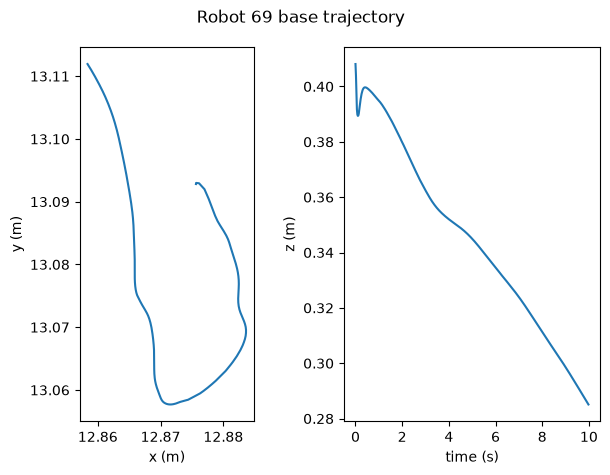

In [6]:
rollouts = Rollout.load(run.eval_file("command_grid"))

n_robot = len(rollouts.alive)
survive_count = np.sum(rollouts.alive)
survival_rate = np.mean(rollouts.alive)

lin_vel_error = metrics.lin_vel_error(rollouts)

print(f"Survival rate is {survival_rate:.1%} ({np.sum(rollouts.alive)} out of {n_robot} evaluations alive)")
print(f"Average linear velocity error is {np.mean(lin_vel_error):.2f} (std={np.std(lin_vel_error):.2f})")

robot_id = 69
print(f"Robot {robot_id} command: {rollouts.cmd[robot_id]} (lin vel error: {lin_vel_error[robot_id]:.2f})")

fig, axes = plt.subplots(nrows=1, ncols=2)

time = rollouts.dt * np.arange(0, rollouts.base_pos.shape[1])
base_x = rollouts.base_pos[robot_id, :, 0]
base_y = rollouts.base_pos[robot_id, :, 1]
base_z = rollouts.base_pos[robot_id, :, 2]

axes[0].plot(base_x, base_y)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")

axes[1].plot(time, base_z)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("z (m)")

fig.suptitle(f"Robot {robot_id} base trajectory")
fig.tight_layout()
plt.show()

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

Given the survival rate above (100%: no robot falls on flat terrain), we decided not to add the other training-log tags to the flat-terrain analysis. We use them only for the stairs case.

## 2.1 Baseline performance

In this section you will characterize your baseline policy: how it learned, how well it performs, and discuss whether it could run on a real robot.

First load the training and rollout data:

In [7]:
# TODO: Load your baseline training and rollout data here
baseline_run = run
baseline_train_metrics = train_metrics
baseline_rollouts = rollouts

# Use successful trials for walking metrics; report survival separately.
baseline_survivors = baseline_rollouts.select(baseline_rollouts.alive)

### 2.1a Training performance

**Minimum:** mean reward and mean episode length curves, and the curves of the individual reward terms.

Questions: 
- When does the policy converge, and would more training help? 
- Which reward terms dominate, and which improve first? 
- Explain how you arrived at your baseline: which settings you tuned, what failures you observed along the way, and how you fixed them.

#### Figure 1: training progress

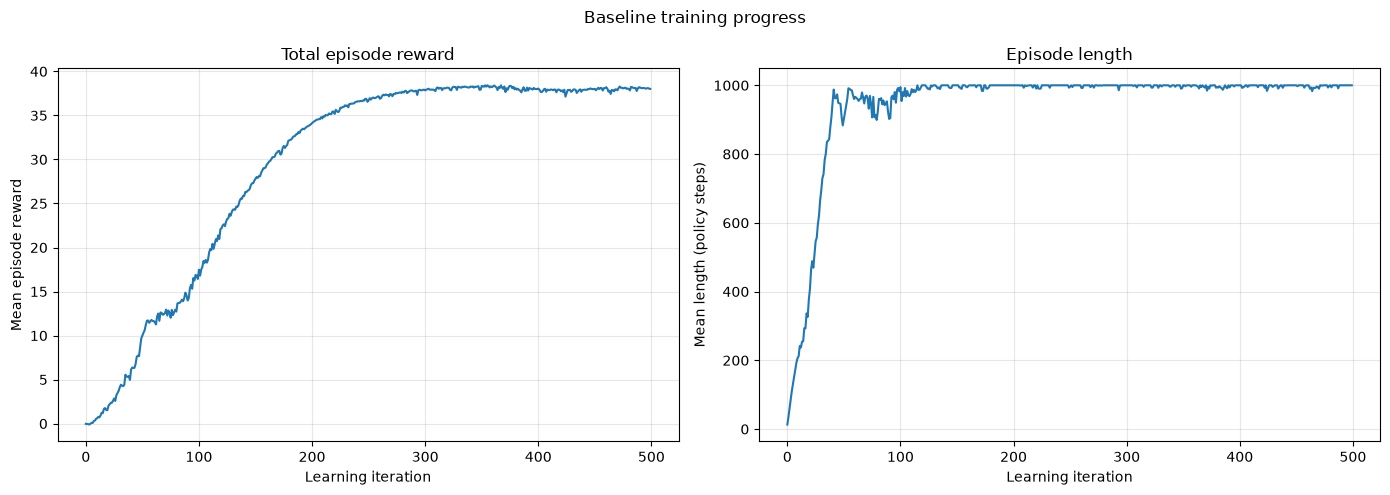

Mean reward: plateau 38.0 (last 50 iterations), max 38.4 at iteration 355, 90% of the plateau at iteration 201
Episode length: 90% of the plateau at iteration 39, first full episode (1000 steps) at iteration 115


In [8]:
# Data: training logs, one point per learning iteration, nothing filtered out.
# Plateau = mean of the last 50 iterations; '90% of plateau' = first iteration covering 90% of the rise to it.
reward_it, mean_reward = baseline_train_metrics["Train/mean_reward"]
length_it, mean_length = baseline_train_metrics["Train/mean_episode_length"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Is the robot earning a better total score as training progresses?
axes[0].plot(reward_it, mean_reward)
axes[0].set_title("Total episode reward")
axes[0].set_ylabel("Mean episode reward")

# Is the robot lasting longer before falling or reaching the time limit?
axes[1].plot(length_it, mean_length)
axes[1].set_title("Episode length")
axes[1].set_ylabel("Mean length (policy steps)")

for ax in axes:
    ax.set_xlabel("Learning iteration")
    ax.grid(alpha=0.3)

fig.suptitle("Baseline training progress")
fig.tight_layout()
plt.show()


def iteration_at_90(iterations, values):
    """First iteration where a curve has covered 90% of its rise to the final plateau (mean of the last 50 iterations)."""
    plateau = np.mean(values[-50:])
    return iterations[np.argmax(values >= values[0] + 0.9 * (plateau - values[0]))]


print(f"Mean reward: plateau {np.mean(mean_reward[-50:]):.1f} (last 50 iterations), "
      f"max {mean_reward.max():.1f} at iteration {reward_it[mean_reward.argmax()]}, "
      f"90% of the plateau at iteration {iteration_at_90(reward_it, mean_reward)}")
print(f"Episode length: 90% of the plateau at iteration {iteration_at_90(length_it, mean_length)}, "
      f"first full episode (1000 steps) at iteration {length_it[np.argmax(mean_length >= 1000)]}")

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure: training progress**

 The robots learn to survive long before they learn to walk well. Episode length reaches 90% of its plateau at iteration 39, and the first full 20 s episodes (1000 steps) appear at iteration 99. The total reward climbs more slowly. It reaches 90% of its plateau at iteration 164 and then levels off around 38.7 (mean of the last 50 iterations), peaking at 39.3 at iteration 381. Early rewards are low partly because short episodes collect few steps, so the reward curve partly follows the episode-length curve.



#### Figure 2: reward terms

track_linear_velocity: 90% of plateau at iter 170, 0.942/s
    94.2% of max, equiv. error 0.086
track_angular_velocity: 90% of plateau at iter 147, 0.960/s
    96.0% of max, equiv. error 0.071
feet_air_time: 90% of plateau at iter 276, 0.151/s


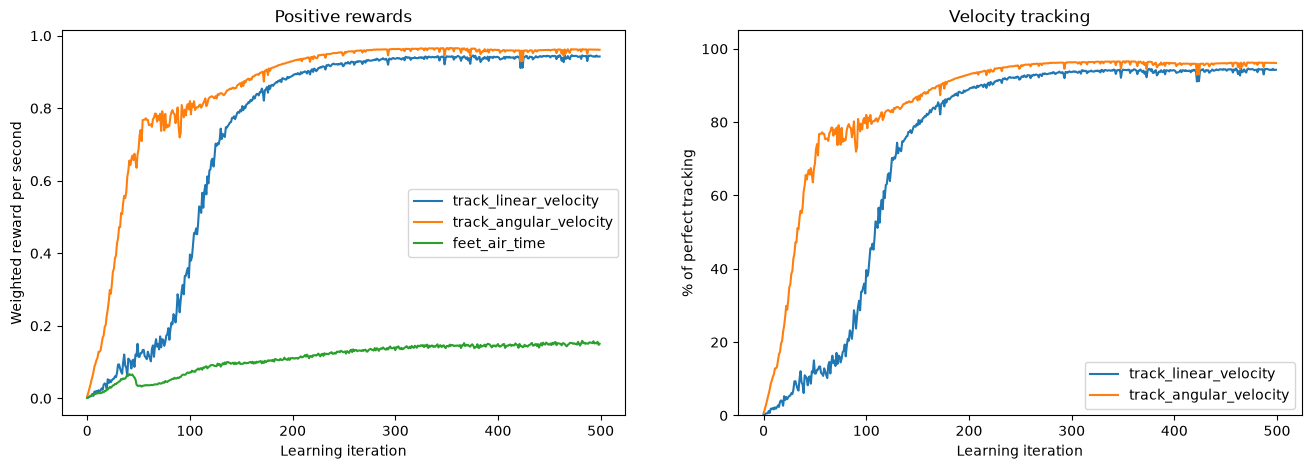

In [9]:
# Data: training logs of the positive reward terms, one point per learning iteration, nothing filtered out.
# Plateau and % of maximum = mean of the last 50 iterations.
import yaml

# BaseLoader reads every value as a string, hence the float() below
with open(baseline_run.path / "params" / "env.yaml") as f:
    reward_cfg = yaml.load(f, Loader=yaml.BaseLoader)["rewards"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
for term, cfg in reward_cfg.items():
    weight = float(cfg["weight"])
    if weight <= 0:
        continue
    iters, vals = baseline_train_metrics[f"Episode_Reward/{term}"]
    ax1.plot(iters, vals, label=term)
    print(f"{term}: 90% of plateau at iter {iteration_at_90(iters, vals)}, {np.mean(vals[-50:]):.3f}/s")
    if term.startswith("track_"):
        ratio = np.mean(vals[-50:]) / weight
        error = float(cfg["params"]["std"]) * np.sqrt(-np.log(ratio))  # invert exp(-e^2/std^2)
        ax2.plot(iters, 100 * vals / weight, label=term)
        print(f"    {100 * ratio:.1f}% of max, equiv. error {error:.3f}")

ax1.set(title="Positive rewards", xlabel="Learning iteration", ylabel="Weighted reward per second")
ax2.set(title="Velocity tracking", xlabel="Learning iteration", ylabel="% of perfect tracking", ylim=(0, 105))
ax1.legend()
ax2.legend()
plt.show()

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure: rewards**

Yaw tracking is learned first (90% of its plateau at iteration 94), followed by linear tracking (iteration 123). The air-time bonus keeps growing slowly until about iteration 236. We show only the tracking terms as a percentage (with 1 corresponding to perfect tracking for the whole 20 s). For feet air time instead, there is no meaningful maximum (four feet in the air would mean jumping), so it stays in absolute value.

Reading the percentage. The kernel $\exp(-e^2/\sigma^2)$ is flat near zero, so 95.6% and 97.2% still mean errors of 0.107 m/s and 0.084 rad/s.

#### Figure 3: penalty terms

body_angular_velocity_penalty: -0.021/s, largest magnitude -0.082 at iter 115
joint_torques: -0.030/s, largest magnitude -0.057 at iter 41
leg_contact_penalty: -0.000/s, largest magnitude -0.104 at iter 41
base_contact_penalty: -0.000/s, largest magnitude -0.000 at iter 13
body_linear_velocity_penalty: -0.019/s, largest magnitude -0.054 at iter 122
body_tilt: -0.001/s, largest magnitude -0.063 at iter 41
action_rate: -0.081/s, largest magnitude -0.259 at iter 122


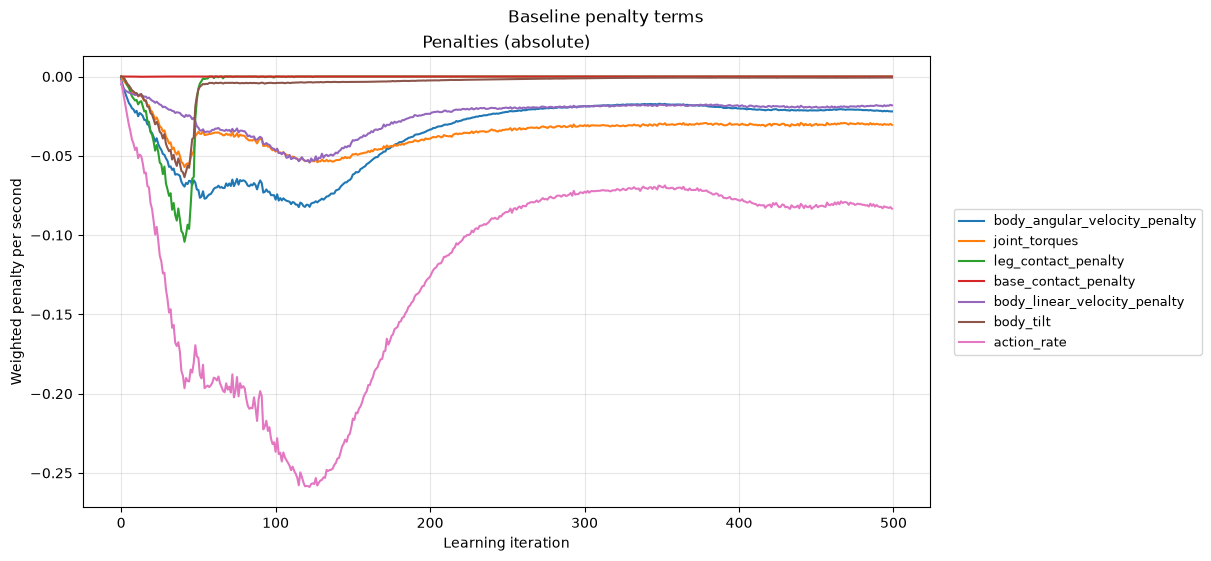

In [10]:
# Data: training logs of the penalty terms (negative weight), one point per learning iteration, nothing filtered out.
# Final value = mean of the last 50 iterations.
fig, ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
fig.suptitle("Baseline penalty terms")

for tag, (iters, vals) in baseline_train_metrics.items():
    if not tag.startswith("Episode_Reward/"):
        continue
    term = tag.removeprefix("Episode_Reward/")
    if float(reward_cfg[term]["weight"]) > 0:
        continue  # positive rewards are in Figure 2

    ax.plot(iters, vals, label=term)
    peak = np.argmax(np.abs(vals))
    print(f"{term}: {np.mean(vals[-50:]):.3f}/s, largest magnitude {vals[peak]:.3f} at iter {iters[peak]}")

ax.set(title="Penalties (absolute)", xlabel="Learning iteration", ylabel="Weighted penalty per second")
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)  # outside, so it never covers the curves

plt.show()


**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure: penalties**

The penalties first grow in magnitude, peaking between iterations 41 and 104, then shrink. Once robots survive longer and move more, they first accumulate more penalty, and only afterwards does the policy learn to move more smoothly. **body_tilt** and **leg_contact_penalty** drop to almost zero around iteration 45. **action_rate** is the largest penalty for the whole run and remains the largest at the end (-0.084 per second); it grows slightly again after iteration 300. **base_contact_penalty** stays essentially zero.

**[ANSWER]**

Survival comes long before good walking. Episode length reaches 90% of its plateau at iteration 39, and the first full 20 s episodes appear at iteration 99. In comparison, the total reward gets to 90% only at iteration 164 and then levels off around 38.7 (Figure 1). Inside the reward, yaw tracking is learned first (iteration 94), then linear tracking (123), and the air-time bonus last (236) (Figure 2). We consider the policy converged at around 250 iterations, since total reward and both tracking terms stay flat from there on, so the 500-iteration budget leaves a large margin. More training would mostly refine air time and smoothness, which still drift slightly. Tracking would gain little: it is already at 95.6% (linear) and 97.2% (yaw) of the maximum, although the kernel $\exp(-e^2/\sigma^2)$ is flat near zero, so these percentages still mean errors of about 0.107 m/s and 0.084 rad/s.



Tracking dominates the reward at about 1.93 per second, compared with 0.16 from air time and about 0.16 lost to penalties. The penalties grow at first, while the robots survive longer and move more, peak between iterations 41 and 104, and then shrink as the policy learns to move smoothly (Figure 3). `body_tilt` and `leg_contact_penalty` fall to almost zero around iteration 45, and `base_contact_penalty` never leaves zero. `action_rate` is the largest penalty for the whole run, ends at -0.084 per second, and grows slightly again after iteration 300.



*TODO: explain how you arrived at the baseline (settings tuned, failures observed, fixes).*

### 2.1b Evaluation performance

**Minimum:**
- velocity tracking: linear and yaw rate errors, overall and per command
- cost of transport
- base stability, with a metric of your own design
- foot ground reaction forces
- a foot contact plot (which foot is on the ground over time)

Questions: 
- Which commands are tracked well, and which are hardest? 
- Which gait did the policy learn, and how can you tell from the contact plot? 
- Is the motion efficient and smooth?

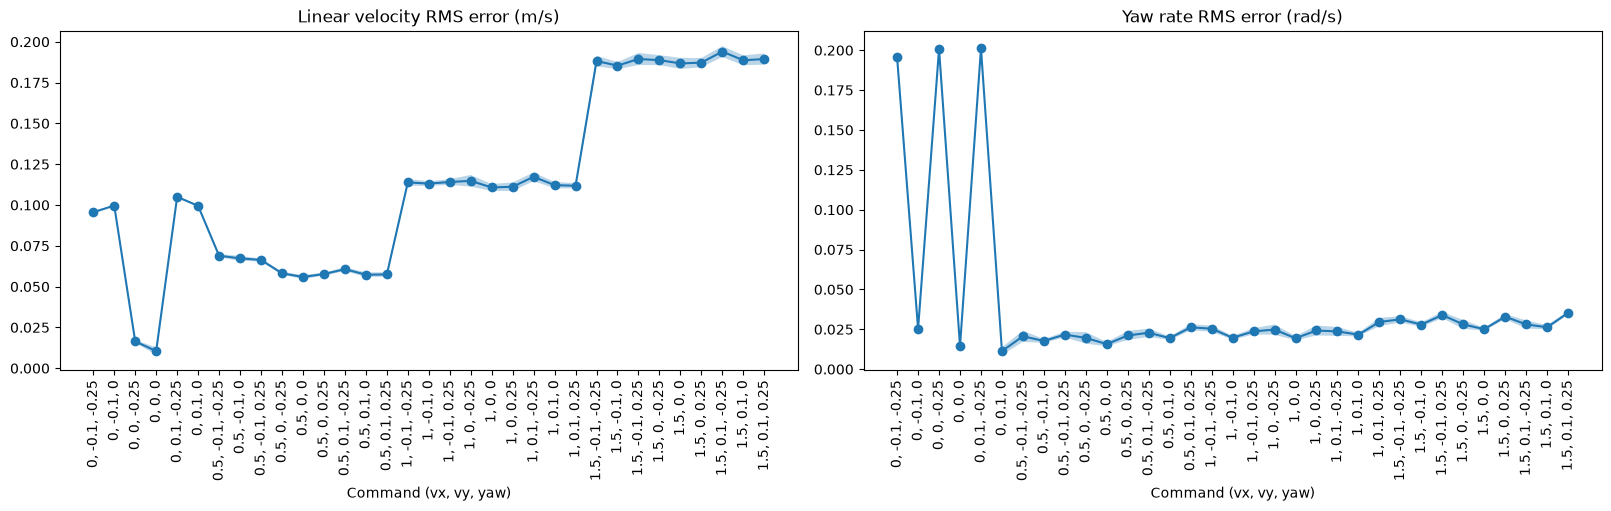

linear 0.112 m/s, yaw 0.040 rad/s


In [11]:
# Figure 4: tracking error per command (line = mean over the 10 trials, band = ± std)
# Data: surviving robots only, whole 20 s rollout (first second included).
# One RMS error per robot, then mean and std over the trials of each command.
r = baseline_survivors
lin_err = metrics.lin_vel_error(r)
yaw_err = metrics.yaw_rate_error(r)
commands = np.unique(r.cmd, axis=0)
labels = [f"{vx:g}, {vy:g}, {wz:g}" for vx, vy, wz in commands]
x = np.arange(len(commands))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
for ax, err, title in [(axes[0], lin_err, "Linear velocity RMS error (m/s)"), (axes[1], yaw_err, "Yaw rate RMS error (rad/s)")]:
    mean = np.array([err[(r.cmd == c).all(axis=1)].mean() for c in commands])
    std = np.array([err[(r.cmd == c).all(axis=1)].std() for c in commands])
    ax.plot(x, mean, marker="o")
    ax.fill_between(x, mean - std, mean + std, alpha=0.3)
    ax.set(title=title, xlabel="Command (vx, vy, yaw)")
    ax.set_xticks(x, labels, rotation=90)
plt.show()
print(f"linear {lin_err.mean():.3f} m/s, yaw {yaw_err.mean():.3f} rad/s")

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 4.** The linear error grows with the requested forward speed (about 0.07, 0.12 and 0.19 m/s at 0.5, 1 and 1.5 m/s), and the yaw error grows the same way, from 0.016 to 0.026 rad/s.
The sign of vy and of the yaw command barely changes either error, so forward speed is what drives tracking quality.

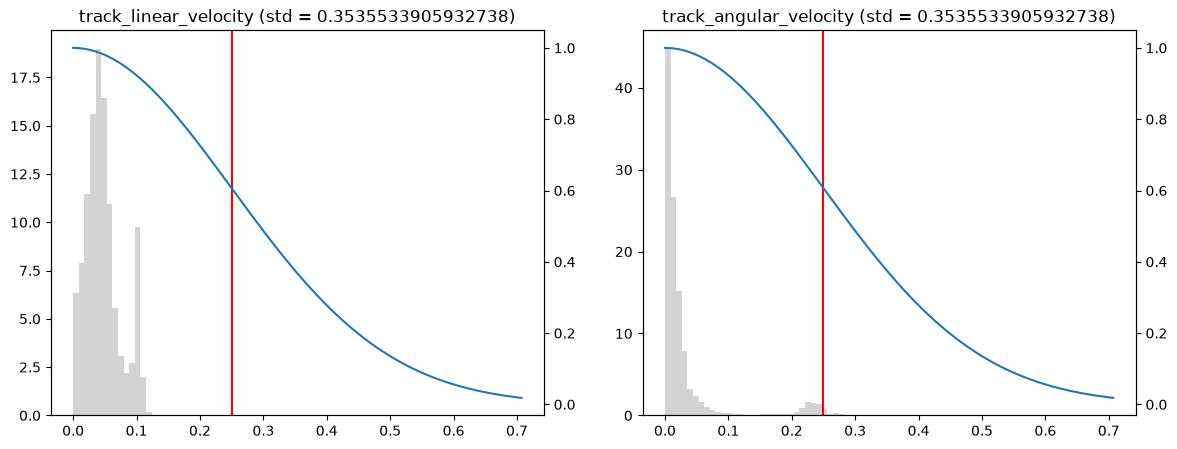

In [12]:
# Figure 5: tracking error histogram vs reward kernel exp(-e^2/std^2).
# If most errors sit left of the red line (max slope) the std can be reduced.
# Data: surviving robots, first second (50 steps) skipped so the start-up does not count.
# Every step of every robot is pooled into one histogram (all commands together).
lin_err = metrics.lin_vel_error_per_step(baseline_survivors)[:, 50:].ravel()
yaw_err = metrics.yaw_rate_error_per_step(baseline_survivors)[:, 50:].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, err, term in zip(axes, [lin_err, yaw_err], ["track_linear_velocity", "track_angular_velocity"]):
    std = float(reward_cfg[term]["params"]["std"])
    e = np.linspace(0, 2 * std, 200)
    ax.hist(err, bins=80, range=(0, 2 * std), density=True, color="lightgray")
    ax.twinx().plot(e, np.exp(-e**2 / std**2))
    ax.axvline(std / np.sqrt(2), color="r")
    ax.set_title(f"{term} (std = {std})")
plt.show()

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 5.** If most errors sit well left of the red line, the kernel is flat there: shrink `std`, but keep the large errors where the kernel still gives reward (> ~0.1).

/tmp/ipykernel_31945/1333019512.py:8: RuntimeWarning: Mean of empty slice
  grid = np.array([[cot[(r.cmd[:, 0] == v) & (r.cmd[:, 1:] == t).all(axis=1)].mean() for v in speeds] for t in turns])
/home/carolina-araujo/Documents/EPFL/Legged_Robots/GO2-Locomotion-RL/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


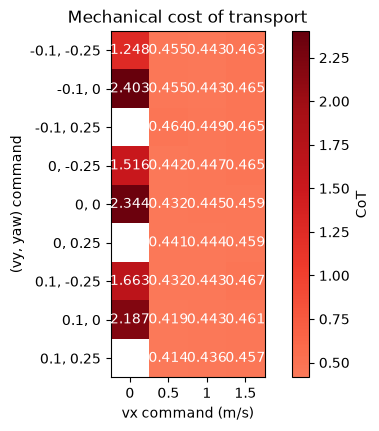

CoT 0.711, action rate 1.112


In [13]:
# Figure 6: mechanical cost of transport for each command (darker red = more expensive)
# Data: surviving robots, whole 20 s rollout (power and speed averaged over all steps).
# One CoT per robot, then the mean over the trials of each command.
from matplotlib.colors import ListedColormap
cot = metrics.cost_of_transport(r)
speeds = np.unique(r.cmd[:, 0])
turns = np.unique(r.cmd[:, 1:], axis=0)  # the 4 (vy, yaw) combinations
grid = np.array([[cot[(r.cmd[:, 0] == v) & (r.cmd[:, 1:] == t).all(axis=1)].mean() for v in speeds] for t in turns])

fig, ax = plt.subplots(figsize=(7, 4.5))
dark_reds = ListedColormap(plt.cm.Reds(np.linspace(0.45, 1, 256)))  # drop the lightest reds so the white text stays readable
im = ax.imshow(grid, cmap=dark_reds)
for j in range(len(turns)):
    for k in range(len(speeds)):
        ax.text(k, j, f"{grid[j, k]:.3f}", ha="center", va="center", color="white")
ax.set(title="Mechanical cost of transport", xlabel="vx command (m/s)", ylabel="(vy, yaw) command")
ax.set_xticks(range(len(speeds)), [f"{v:g}" for v in speeds])
ax.set_yticks(range(len(turns)), [f"{vy:g}, {wz:g}" for vy, wz in turns])
fig.colorbar(im, label="CoT")
plt.show()
print(f"CoT {cot.mean():.3f}, action rate {metrics.action_rate(r).mean():.3f}")

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 6.** The mechanical cost of transport is about 0.43 at 0.5 m/s and drops to about 0.39 at 1 and 1.5 m/s (mean 0.404).
Walking slowly costs more per metre, probably because the gait cycle keeps roughly the same work while covering less distance.

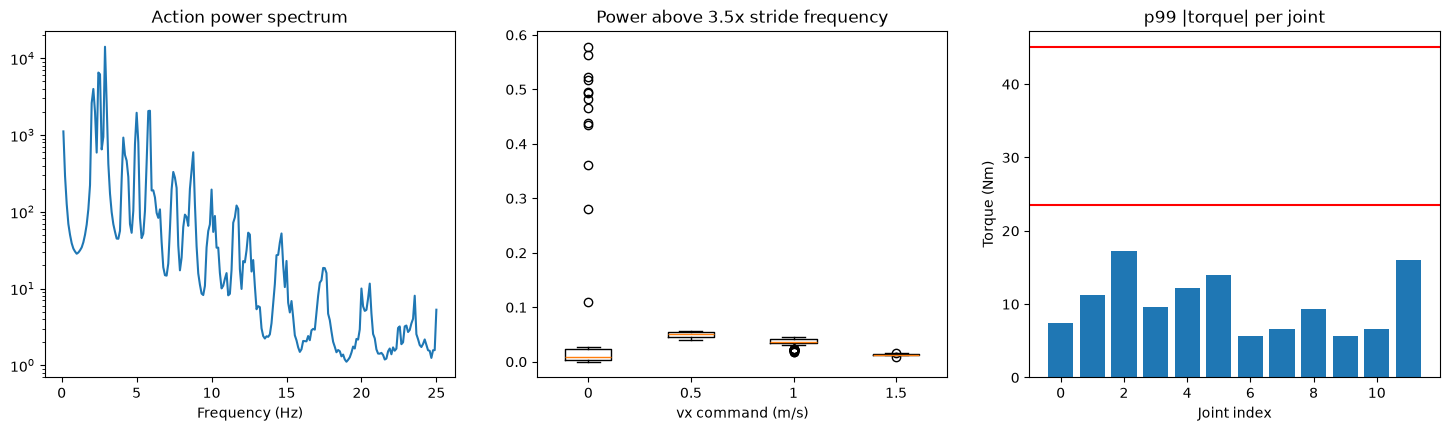

In [14]:
# Figure 7: action smoothness and torque use.
# Action power above 3.5x the stride frequency is jitter; p99 torque per joint is compared to the actuator limits (red).
# Data: surviving robots, first second (50 steps) skipped for the spectrum and the torques,
# whole rollout for the jitter fraction (middle). p99 is taken over all steps and robots together.
cutoff = 3.5 * metrics.stride_frequency(r)
hf = metrics.action_hf_fraction(r, cutoff)
a = r.action[:, 50:] - r.action[:, 50:].mean(axis=1, keepdims=True)
freqs = np.fft.rfftfreq(a.shape[1], r.dt)
psd = (np.abs(np.fft.rfft(a, axis=1)) ** 2).mean(axis=(0, 2))
p99 = np.percentile(np.abs(r.joint_torque[:, 50:]), 99, axis=(0, 1))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].semilogy(freqs[1:], psd[1:])
axes[0].set(title="Action power spectrum", xlabel="Frequency (Hz)")
axes[1].boxplot([hf[r.cmd[:, 0] == v] for v in speeds], tick_labels=[f"{v:g}" for v in speeds])
axes[1].set(title="Power above 3.5x stride frequency", xlabel="vx command (m/s)")
axes[2].bar(range(12), p99)
axes[2].axhline(23.5, color="r")
axes[2].axhline(45, color="r")
axes[2].set(title="p99 |torque| per joint", xlabel="Joint index", ylabel="Torque (Nm)")
plt.show()

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 7.** Large power above 3.5x the stride frequency means jitter: raise `action_rate`. Torque near the red lines (23.5 Nm hip/thigh, 45 Nm calf) means raise `joint_torques`.

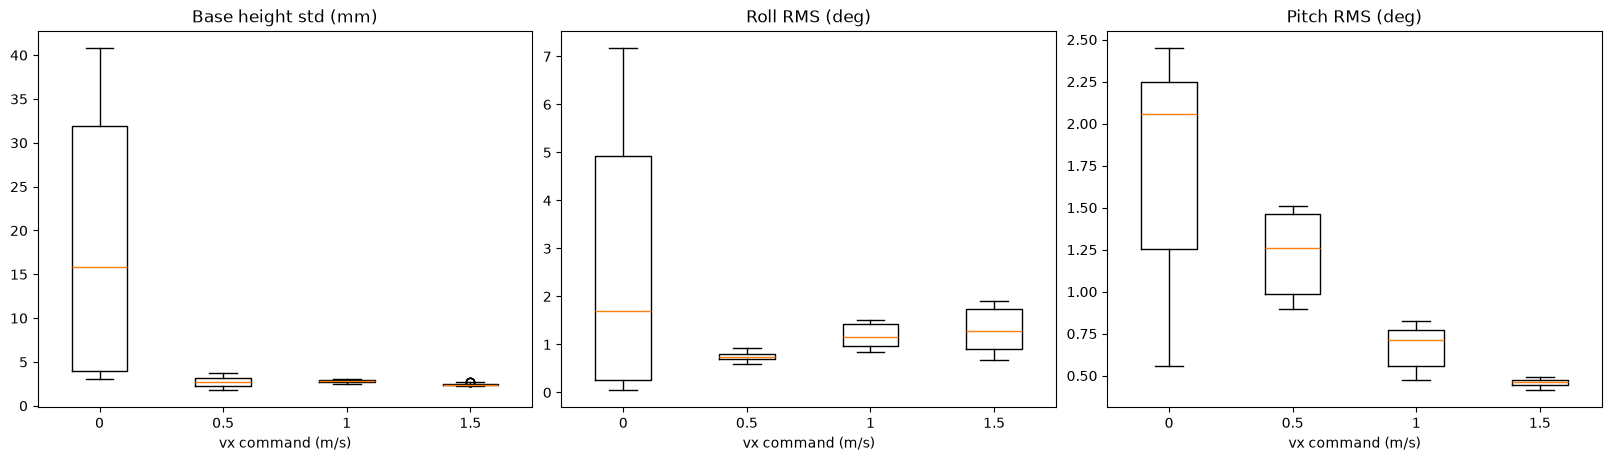

Base height std (mm): 5.491
Roll RMS (deg): 1.337
Pitch RMS (deg): 0.964


In [15]:
# Figure 8: base stability, skipping the first second (50 steps) where the robot starts moving.
# Height: std around its own mean. Roll and pitch: RMS around 0 (like the body_tilt reward), so a constant lean also counts.
roll_pitch = np.degrees(metrics.roll_pitch_per_step(r)[:, 50:])
stability = {
    "Base height std (mm)": 1000 * r.base_pos[:, 50:, 2].std(axis=1),
    "Roll RMS (deg)": np.sqrt(np.mean(roll_pitch[..., 0] ** 2, axis=1)),
    "Pitch RMS (deg)": np.sqrt(np.mean(roll_pitch[..., 1] ** 2, axis=1)),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")
for ax, (title, values) in zip(axes, stability.items()):
    ax.boxplot([values[r.cmd[:, 0] == v] for v in speeds], tick_labels=[f"{v:g}" for v in speeds])
    ax.set(title=title, xlabel="vx command (m/s)")
plt.show()
for title, values in stability.items():
    print(f"{title}: {values.mean():.3f}")

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 8.** Base height and roll vary more as speed grows (height std 1.9 to 2.6 mm, roll 0.3 to 0.6 deg), but both stay small: the body is essentially level.
Pitch goes the other way (1.3 to 0.4 deg) because it is mostly a constant lean of about 1.2 deg at 0.5 m/s that disappears at 1.5 m/s, while the pitch oscillation stays near 0.3 deg at every speed.

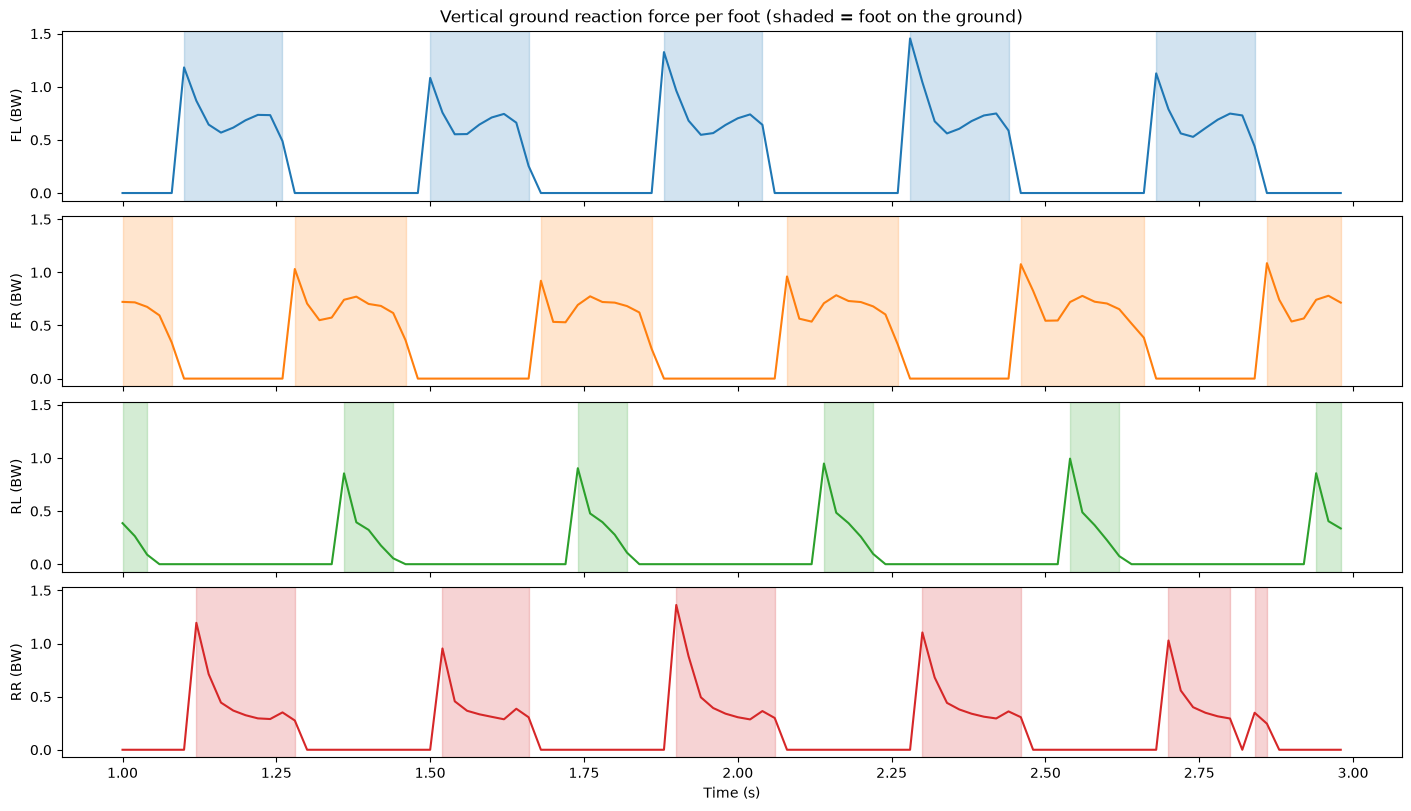

duty factor 0.52, stride frequency 3.25 Hz, support 0.992 BW


In [16]:
# Figure 9: foot forces and contacts of one walk at vx = 1 m/s, between 1 and 3 s (one row per foot, shaded = stance)
i = np.where(r.cmd[:, 0] == 1.0)[0][0]
t = np.arange(r.base_pos.shape[1]) * r.dt
w = (t >= 1) & (t < 3)
feet = ["FL", "FR", "RL", "RR"]
force = -r.foot_grf[i, w, :, 2] / metrics.body_weight(r)[i]  # sensor z is negative, flip to upward force
contact = r.foot_contact[i, w]

fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True, sharey=True, layout="constrained")
for foot, (ax, color) in enumerate(zip(axes, ["tab:blue", "tab:orange", "tab:green", "tab:red"])):
    ax.fill_between(t[w], 0, 1, where=contact[:, foot], color=color, alpha=0.2, transform=ax.get_xaxis_transform(), step="mid")
    ax.plot(t[w], force[:, foot], color=color)
    ax.set_ylabel(f"{feet[foot]} (BW)")
axes[0].set_title("Vertical ground reaction force per foot (shaded = foot on the ground)")
axes[-1].set_xlabel("Time (s)")
plt.show()
print(f"duty factor {metrics.duty_factor(r).mean():.2f}, stride frequency {np.nanmean(metrics.stride_frequency(r)):.2f} Hz, support {metrics.weight_support(r).mean():.3f} BW")

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 9.** The diagonal pairs FL/RR and FR/RL touch down together (contacts agree 83-87% of the time), so the policy learned a trot at 3 Hz with a duty factor of 0.39.
Each stance peaks at about 1.6 body weights in this window, and averaged over the episode the four feet carry 0.994 body weights, as expected for steady walking.

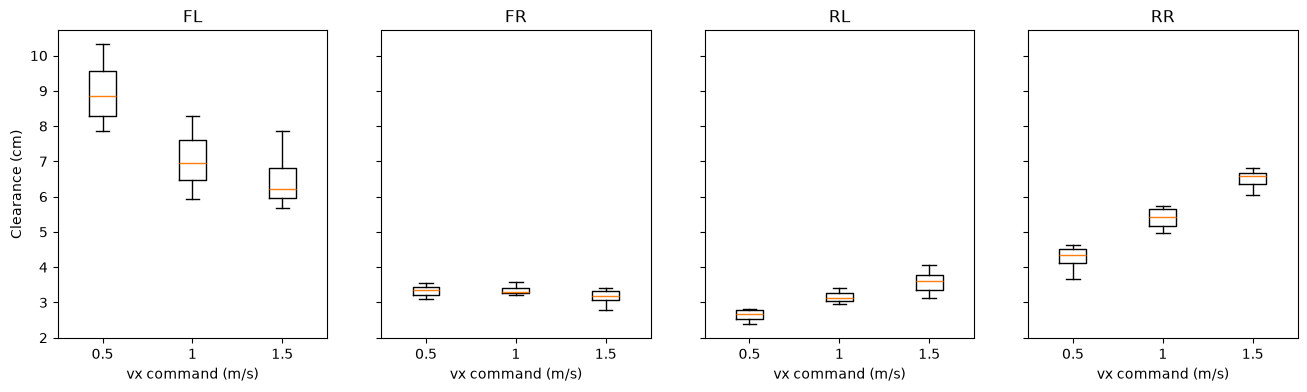

In [207]:
# Figure 10: foot clearance per foot and commanded speed (no reward term sets the step height).
# Data: surviving robots, whole rollout; swings shorter than 2 steps are contact flickers and are skipped.
clear = np.full((r.num_robots, 4), np.nan)
for i in range(r.num_robots):
    for f in range(4):
        swings = metrics.phases(r.foot_contact[i, :, f], stance=False)
        peaks = [r.foot_height[i, s:e, f].max() for s, e in swings if e - s >= 2]
        if peaks:
            clear[i, f] = 100 * (np.mean(peaks) - metrics.FOOT_RADIUS)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for f, (ax, name) in enumerate(zip(axes, ["FL", "FR", "RL", "RR"])):
    data = [clear[r.cmd[:, 0] == v, f] for v in speeds]
    ax.boxplot([d[~np.isnan(d)] for d in data], tick_labels=[f"{v:g}" for v in speeds])
    ax.set(title=name, xlabel="vx command (m/s)")
axes[0].set_ylabel("Clearance (cm)")
plt.show()

**[TO DELETE]** *Draft notes, move what we need into the [ANSWER] cell before submitting.*

**Figure 10.** No reward term sets the step height. Compare the feet (diagonal asymmetry) and keep the low ones in mind for stairs.

**[ANSWER]**

No robot falls on flat terrain (100% survival), and tracking depends almost only on forward speed (Figure 4): the linear RMS error grows from 0.07 m/s at vx = 0.5 to 0.19 m/s at 1.5 m/s and the yaw error from 0.016 to 0.026 rad/s, while the sign of vy or yaw barely matters. These errors sit far left of the steepest point of the tracking kernel (Figure 5, 0.35 for std = 0.5), where the reward is almost flat, so a smaller `std` would probably push them down. The policy learned a trot (Figure 9): diagonal feet touch down together (83 to 87% agreement) at 3 Hz with a duty factor of 0.39, and the feet carry 0.994 body weights with soft landings (stance peaks of 1.14 body weights). The trot is not symmetric, though (Figure 10): FL and RR lift 4 to 9 cm while FR and RL lift only about 3 cm, and no reward term sets the step height, which may cause trips on stairs.

Slow walking costs more per metre: the mechanical cost of transport is about 0.43 at 0.5 m/s and 0.39 at 1 and 1.5 m/s (Figure 6). `action_rate` is still the largest training penalty (mean action change 1.34), but most of the action power sits at the 3 Hz stride frequency and its harmonics, and only 1 to 4% lies above 3.5 times the stride frequency (Figure 7), so the policy follows the gait rather than jittering. Torques stay far from saturation (largest 99th percentile about 15 Nm against limits of 23.5 and 45 Nm). The body stays almost level (Figure 8): base height varies by 1.9 to 2.6 mm and roll by 0.3 to 0.6 deg, and pitch drops from 1.3 to 0.4 deg RMS with speed because it is mostly a constant lean at 0.5 m/s.

### 2.1c Discussion: deployability

Given your previous observations, would your policy work on the real Go2? 
Discuss:
- **Observations:** can each observation be obtained on the real robot, and how noisy would it be?
- **Actions:** are the commanded motions realistic for the motors (look at torques, joint velocities and action smoothness)?
- **Evaluation on hardware:** which of your metrics could you measure on the real robot, and how?
- **Sim-to-real:** which reward terms or settings did you add to make the policy more transferable, and what is still missing?


**[ANSWER]** *Write your discussion here, 3 paragraphs max*

## 2.2 Controlled experiment

In this section you will describe and report the results of your controlled experiment in section 1.5 of notebook 01 like a short scientific study.

### 2.2a Questions and hypotheses

State your research question and your hypotheses:
- **Null hypothesis $H_0$:** the change has no effect on the metrics you chose.
- **Alternative hypothesis $H_1$:** the change affects the metrics, in a direction you predict, and why.

Name the metrics that will enable to reject the null hypothesis in favor of your alternative hypothesis, answering your research question.

**[ANSWER]** *Write your question, hypotheses, and metrics here.*

### 2.2b Methods

Describe exactly what differs between your baseline and your variant, what was held fixed (training budget, evaluation commands, seeds), how many runs each configuration has, and how you decide whether a difference is real (e.g. larger than the spread between seeds). 
Mention possible confounders.

**[ANSWER]** *Write your methods here. 2 paragraphs max.*

### 2.2c Experimental results

**Minimum:** at least 3 figures comparing baseline and variant, using training curves and/or evaluation metrics. 
Show both configurations in the same figure where possible, with the same axes.

In [208]:
# TODO: Load your variant training and rollout data here

In [209]:
# TODO: create your figures here

**[ANSWER]** *Describe what each figure shows here. 2 paragraphs max.*

### 2.2e Discussion

What did you expect, and what did you not expect? 
Do the results support $H_1$ and reject $H_0$, and how conclusive are they (number of runs, size of the difference compared to the variation between runs)? 
Explain the mechanism: how does your change lead to the effect you measured? 
What would you test next?

**[ANSWER]** *Describe your interpretations here. Linking your observations back to the course or the literature is encouraged! 3 paragraphs max.*